In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

from utils import get_color_limits
from PIL import Image

In [2]:
coner_track_parameters = {
    "maxCorners" : 10,
    "qualityLevel": 0.3,
    "minDistance": 7,
    "blockSize": 7,
}

lk_parameters = {
    "winSize": (20,20),
    "maxLevel": 2,
    "criteria": (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.05),
}

In [5]:
def detect_blue_object(image):
    # En OpenCV el orden de color por defecto es BGR, así que [255, 0, 0] es Azul puro.
    # azul_bajo = np.array([100, 50, 50])
    # azul_alto = np.array([130, 255, 255])


    blue = [255,0,0]
    lower_limit, upper_limit = get_color_limits(blue)

    blanco_bajo = np.array([0, 0, 110], dtype=np.uint8)
    blanco_alto = np.array([179, 90, 255], dtype=np.uint8)

    image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(image_hsv, lower_limit, upper_limit)

    not_light = cv2.inRange(image_hsv, blanco_bajo, blanco_alto)
    mask_not_light = cv2.bitwise_not(not_light)
    final_mask = cv2.bitwise_and(mask, mask_not_light)

    # kernel = np.ones((25, 25), np.uint8)
    # mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    # mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    mask_ = Image.fromarray(final_mask)
    bbox = mask_.getbbox()

    if bbox is not None:
        x1, y1, x2, y2 = bbox
        # Dibuja el rectángulo verde
        image_with_box = cv2.rectangle(image.copy(), (x1, y1), (x2, y2), (0, 255, 0), 2)
        return image_with_box, mask

    return image, mask

In [7]:
cam = cv2.VideoCapture(0)

while True:
    check, frame = cam.read()
    new_frame, _  = detect_blue_object(frame)

    cv2.imshow('video', new_frame)
    image_test = frame

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break



QFontDatabase: Cannot find font directory /home/rosalind/Documents/arduino_q3_hackaton/.venv/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/rosalind/Documents/arduino_q3_hackaton/.venv/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/rosalind/Documents/arduino_q3_hackaton/.venv/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/rosalind/Documents/arduino_q3_hackaton/.venv/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io

In [ ]:
|

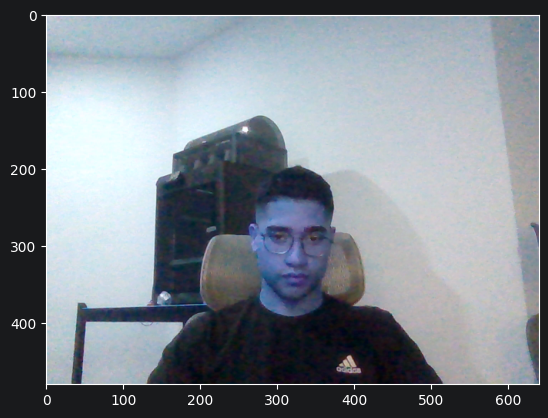

In [101]:
plt.imshow(frame)

In [102]:
marked_image, mask = detect_blue_object(frame)

In [103]:
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

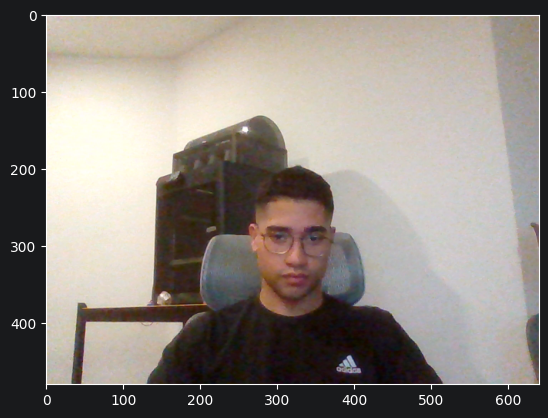

In [104]:
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

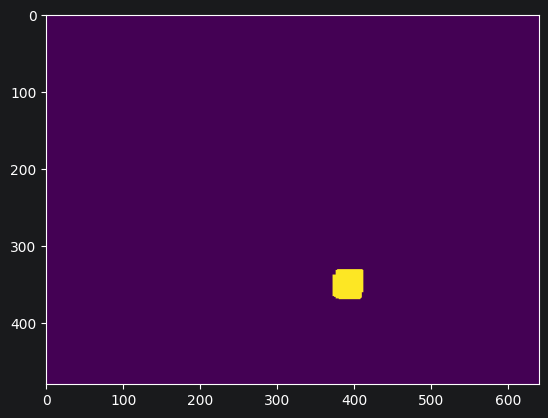

In [106]:
plt.imshow(mask)

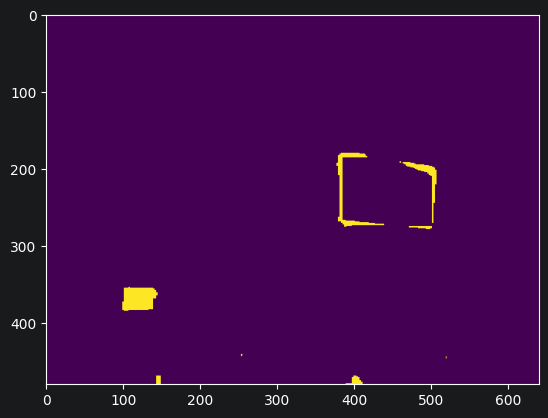

In [70]:
plt.imshow(mask)

In [11]:
for cnt in contours:
        area = cv2.contourArea(cnt)
        if area > 500:  # Filtra el ruido y píxeles sueltos
            x, y, w, h = cv2.boundingRect(cnt)
            cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

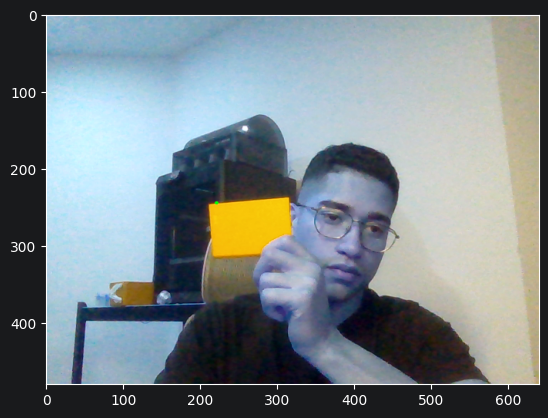

In [12]:
plt.imshow(frame)